[Open in Colab](https://colab.research.google.com/github/moonlovist/EEEA-ML/blob/main/sessions/session02/lab/en/01_Demos_EN.ipynb)

# Lab 02 · Guided experiments
Ting Tan · EEEA

From regression to classification.

## Getting started
Run cells from top to bottom with **Shift+Enter**. No GPU or API key is needed. Data are included; no data upload is required.

**Colab:** open [Colab](https://colab.research.google.com/), choose **File → Upload notebook**, import this `.ipynb`, and connect to a Python runtime. Save/download your edited notebook before leaving.

**Local Jupyter:** in a terminal in the extracted folder:
```
python -m pip install -r requirements.txt
python -m notebook
```
If Jupyter is already configured, use your existing environment.

Run the import cell below. If later results look inconsistent, restart the kernel/runtime and run all cells in order. Read an error from its last line upward.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_curve, roc_auc_score, precision_recall_curve,
    average_precision_score
)
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11})

def sigmoid(z):
    z = np.asarray(z, dtype=float)
    # Equivalent to 1 / (1 + exp(-z)), with stable evaluation.
    return np.exp(-np.logaddexp(0.0, -z))

def mean_bce(x, c, w, b):
    z = w * x + b
    return float(np.mean(np.logaddexp(0.0, z) - c * z))

print("Python / NumPy / Matplotlib / scikit-learn: OK")

Python / NumPy / Matplotlib / scikit-learn: OK


**Python reminders:** `np.array` stores a numerical vector; `*` multiplies element by element; `np.mean` computes a mean. `p >= 0.5` produces booleans; `np.sum(condition)` counts the `True` values. Indices start at 0.

The provided `sigmoid` and `mean_bce` functions implement the lecture formulas stably. All logarithms are natural.

## D1 · One linear-regression update
Use the three observations from the lecture. Locate each mathematical operation in the code.
$$r_i=wx_i+b-y_i,\quad J=\frac{1}{2n}\sum_i r_i^2.$$
$$g_w=\frac1n\sum_i r_ix_i,\quad g_b=\frac1n\sum_i r_i.$$
Both gradients use the **old** parameters. The final assignment updates both together.

In [2]:
x = np.array([1., 2., 3.])
y = np.array([12., 19., 32.])
w, b, eta = 10.0, 0.0, 0.1

prediction = w * x + b
residual = prediction - y
loss = np.mean(residual ** 2) / 2
dw = np.mean(residual * x)
db = np.mean(residual)
w_new, b_new = w - eta * dw, b - eta * db
new_loss = np.mean((w_new * x + b_new - y) ** 2) / 2

print("residual =", residual)
print("J =", loss, "| dw =", dw, "| db =", db)
print("w_new =", w_new, "| b_new =", b_new)
print("J_new =", new_loss)
assert np.allclose([dw, db, w_new, b_new, new_loss],
                   [-2, -1, 10.2, 0.1, 6.83 / 6])

residual = [-2.  1. -2.]
J = 1.5 | dw = -2.0 | db = -1.0
w_new = 10.2 | b_new = 0.1
J_new = 1.1383333333333343


**Check:** residuals `[-2, 1, -2]`, gradients `(-2, -1)`, parameters `(10.2, 0.1)`, new loss `1.1383333333`.

Execute the plot. Dashed segments show original residuals. Why does a negative gradient increase the parameter?

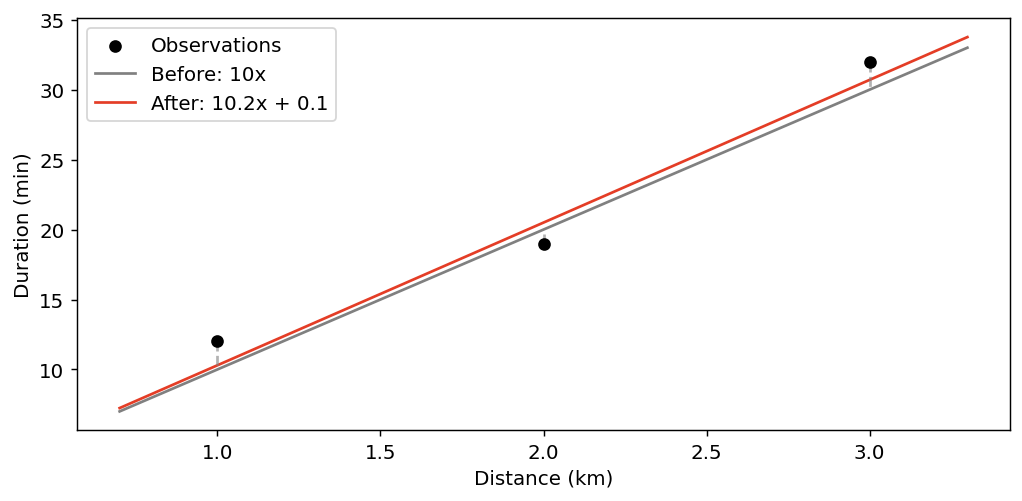

In [3]:
grid = np.linspace(0.7, 3.3, 100)
plt.scatter(x, y, color="black", label="Observations", zorder=3)
plt.plot(grid, 10 * grid, color="gray", label="Before: 10x")
plt.plot(grid, w_new * grid + b_new, color="#e43d26",
         label="After: 10.2x + 0.1")
for xi, yi, pi in zip(x, y, prediction):
    plt.plot([xi, xi], [yi, pi], "--", color="gray", alpha=0.6)
plt.xlabel("Distance (km)")
plt.ylabel("Duration (min)")
plt.legend()
plt.tight_layout()
plt.show()

## D2 · Train a logistic classifier
The label is $c=1$ if duration exceeds 30 minutes, and $c=0$ otherwise.
$$p_i=\sigma(wx_i+b),\quad g_w=\frac1n\sum_i(p_i-c_i)x_i,\quad g_b=\frac1n\sum_i(p_i-c_i).$$
Start at $w=b=0$ and run one update. The objective is **mean binary cross-entropy**.

In [4]:
x_binary = np.arange(1., 7.)
duration = np.array([12., 19., 32., 29., 48., 57.])
c_binary = (duration > 30).astype(int)
w, b, eta = 0.0, 0.0, 0.1

p = sigmoid(w * x_binary + b)
dw = np.mean((p - c_binary) * x_binary)
db = np.mean(p - c_binary)
w_new, b_new = w - eta * dw, b - eta * db

print("c =", c_binary, "| p =", p)
print("dw =", dw, "| db =", db)
print("J_before =", mean_bce(x_binary, c_binary, w, b))
print("w_new =", w_new, "| b_new =", b_new)
print("J_after =", mean_bce(x_binary, c_binary, w_new, b_new))
assert np.allclose([dw, db, w_new, b_new], [-7/12, 0, 7/120, 0])
assert np.isclose(mean_bce(x_binary, c_binary, w_new, b_new),
                  0.6655477879161796)

c = [0 0 1 0 1 1] | p = [0.5 0.5 0.5 0.5 0.5 0.5]
dw = -0.5833333333333334 | db = 0.0
J_before = 0.6931471805599453
w_new = 0.05833333333333334 | b_new = 0.0
J_after = 0.6655477879161796


**Check:** `dw = -7/12`, `db = 0`. The loss falls from `log(2) ≈ 0.693147` to `0.6655477879`.

Repeat the same rule 5,000 times. The left graph shows optimisation; the right graph shows the learned probabilities.

w = 1.21344579, b = -4.24682298, BCE = 0.4129978434


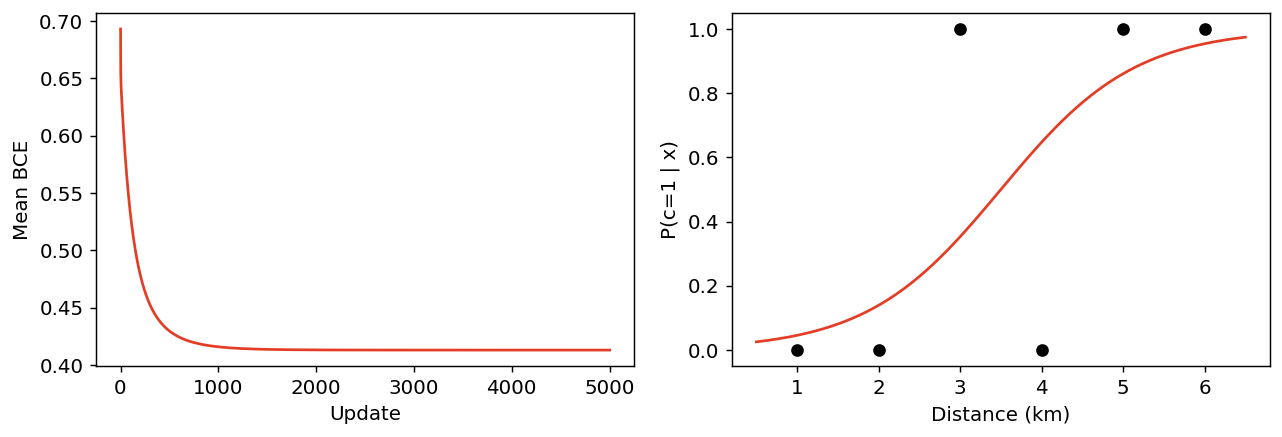

In [5]:
w, b = 0.0, 0.0
eta, updates = 0.1, 5000
losses = [mean_bce(x_binary, c_binary, w, b)]
for step in range(updates):
    p = sigmoid(w * x_binary + b)
    dw = np.mean((p - c_binary) * x_binary)
    db = np.mean(p - c_binary)
    w, b = w - eta * dw, b - eta * db
    losses.append(mean_bce(x_binary, c_binary, w, b))

print(f"w = {w:.8f}, b = {b:.8f}, BCE = {losses[-1]:.10f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(losses, color="#e43d26")
axes[0].set(xlabel="Update", ylabel="Mean BCE")
grid = np.linspace(0.5, 6.5, 200)
axes[1].plot(grid, sigmoid(w * grid + b), color="#e43d26")
axes[1].scatter(x_binary, c_binary, color="black")
axes[1].set(xlabel="Distance (km)", ylabel="P(c=1 | x)", ylim=(-0.05, 1.05))
plt.tight_layout()
plt.show()
assert np.isclose(losses[-1], 0.4129978434013483)

**Observe:** final BCE ≈ `0.412998`. Labels at x=3 and x=4 conflict with a perfect increasing rule.

1. What stays fixed when the trained model predicts a new input?
2. Why are labels 0/1 while the probability curve is continuous?
3. Does decreasing training loss establish performance on new data?

## D3 · Evaluate decisions and score ranking
Use the eight validation scores from the lecture, independently of the six training cases above. Predict 1 when $p\geq\tau$, **including equality**.

`sklearn.confusion_matrix` uses **true classes as rows**. Transpose it with label order `[1,0]` to match the lecture: **predicted class in rows**, observed class in columns, TP in the upper-left cell.

Read each metric's denominator. In this lab, a zero denominator gives metric value 0; this is an explicit reporting convention.

In [6]:
scores = np.array([.95, .85, .70, .60, .45, .30, .20, .10])
truth = np.array([1, 1, 0, 1, 1, 0, 0, 0])

print("tau   TP FP FN TN   accuracy precision recall F1 specificity")
for tau in [0.5, 0.8]:
    predicted = (scores >= tau).astype(int)
    # sklearn: rows = true class, columns = predicted class.
    # labels=[1,0], then transpose to match the lecture orientation.
    matrix = confusion_matrix(truth, predicted, labels=[1, 0]).T
    tp, fp, fn, tn = matrix.ravel()
    accuracy = accuracy_score(truth, predicted)
    precision = precision_score(truth, predicted, zero_division=0)
    recall = recall_score(truth, predicted, zero_division=0)
    f1 = f1_score(truth, predicted, zero_division=0)
    specificity = tn / (tn + fp)
    print(f"{tau:.1f}   {tp:2d} {fp:2d} {fn:2d} {tn:2d}   "
          f"{accuracy:.3f}    {precision:.3f}     {recall:.3f}  "
          f"{f1:.3f}  {specificity:.3f}")

tau   TP FP FN TN   accuracy precision recall F1 specificity
0.5    3  1  1  3   0.750    0.750     0.750  0.750  0.750
0.8    2  0  2  4   0.750    1.000     0.500  0.667  1.000


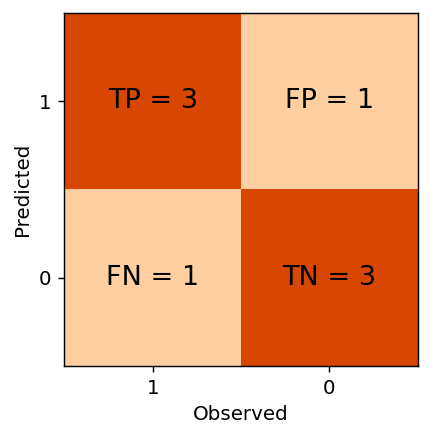

In [7]:
predicted = (scores >= 0.5).astype(int)
matrix = confusion_matrix(truth, predicted, labels=[1, 0]).T
fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.imshow(matrix, cmap="Oranges", vmin=0, vmax=4)
for row in range(2):
    for col in range(2):
        name = [["TP", "FP"], ["FN", "TN"]][row][col]
        ax.text(col, row, f"{name} = {matrix[row, col]}",
                ha="center", va="center", fontsize=15)
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=[1, 0], yticklabels=[1, 0],
       xlabel="Observed", ylabel="Predicted")
plt.tight_layout()
plt.show()

At threshold 0.5, TP/FP/FN/TN = 3/1/1/3. At 0.8: 2/0/2/4. Accuracy stays 0.75, while recall falls from 0.75 to 0.5.

ROC and PR receive **probability scores**, not thresholded labels. AP weights precision by recall increments; it is not trapezoidal PR area.

ROC-AUC = 0.8750; AP = 0.8875


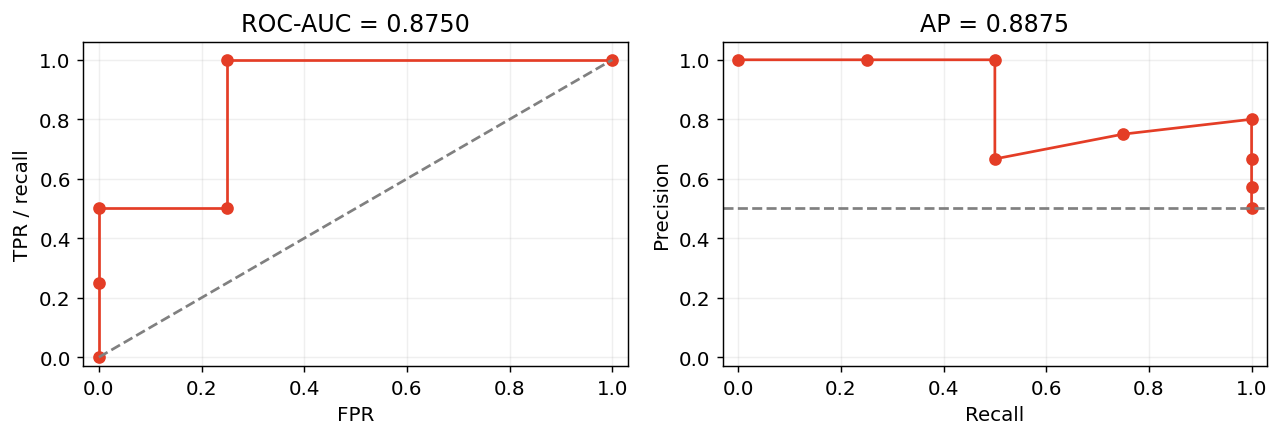

In [8]:
fpr, tpr, roc_thresholds = roc_curve(truth, scores)
precision, recall, pr_thresholds = precision_recall_curve(truth, scores)
auc = roc_auc_score(truth, scores)
ap = average_precision_score(truth, scores)
print(f"ROC-AUC = {auc:.4f}; AP = {ap:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(fpr, tpr, "o-", color="#e43d26")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(xlabel="FPR", ylabel="TPR / recall", title=f"ROC-AUC = {auc:.4f}")
axes[1].plot(recall, precision, "o-", color="#e43d26")
axes[1].axhline(np.mean(truth), linestyle="--", color="gray")
axes[1].set(xlabel="Recall", ylabel="Precision",
            title=f"AP = {ap:.4f}")
for ax in axes:
    ax.set(xlim=(-0.03, 1.03), ylim=(-0.03, 1.06))
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
assert np.isclose(auc, 0.875) and np.isclose(ap, 0.8875)

**Check:** ROC–AUC = 0.875; AP = 0.8875.

1. Which additional positive case is missed when the threshold rises?
2. Does ROC–AUC change when only that decision threshold changes?
3. Why can equal accuracy hide different practical consequences?

Continue with `02_Exercises_EN.ipynb`.

## References
- [Stanford CS229: supervised learning](https://see.stanford.edu/materials/aimlcs229/cs229-notes1.pdf)
- [scikit-learn: confusion matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)
- [scikit-learn: precision–recall](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html)